In [611]:
#imports
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 

from matplotlib.ticker import FormatStrFormatter

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.inspection import permutation_importance

import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout


SEED = 2495639
keras.utils.set_random_seed(SEED)

In [612]:
#load dataset
df = pd.read_csv('data.csv', keep_default_na=False, na_values=[''])

In [613]:
#order dataset columns to have numeric columns first, followed by categorical columns
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

df = df[numeric_cols + categorical_cols]

C:\Users\monte\AppData\Local\Temp\ipykernel_25908\4140947778.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


In [614]:
df.head()

,age,bmi,diabetes,hypertension,heart_disease,asthma,daily_steps,sleep_hours,stress_level,doctor_visits_per_year,hospital_admissions,medication_count,insurance_coverage_pct,previous_year_cost,annual_medical_cost,gender,smoker,physical_activity_level,insurance_type,city_type
0,69,29.4,1,0,0,0,14825,4.4,8,1,0,4,80,10885,2645.50,Male,No,Medium,Private,Semi-Urban
1,32,22.9,1,0,0,0,3620,6.0,7,4,3,0,64,18722,10959.70,Female,No,Medium,Government,Semi-Urban
2,89,25.7,0,0,0,0,10578,4.5,7,2,0,3,0,4196,8409.80,Male,No,High,None,Urban
3,78,31.9,0,1,0,0,6226,8.6,9,6,1,7,70,11128,7996.62,Male,Yes,Low,Government,Urban
4,38,27.7,0,0,0,0,6253,5.7,3,6,0,6,77,15110,3202.52,Male,No,High,Private,Urban


In [615]:
#data exploration
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      5000 non-null   int64  
 1   bmi                      5000 non-null   float64
 2   diabetes                 5000 non-null   int64  
 3   hypertension             5000 non-null   int64  
 4   heart_disease            5000 non-null   int64  
 5   asthma                   5000 non-null   int64  
 6   daily_steps              5000 non-null   int64  
 7   sleep_hours              5000 non-null   float64
 8   stress_level             5000 non-null   int64  
 9   doctor_visits_per_year   5000 non-null   int64  
 10  hospital_admissions      5000 non-null   int64  
 11  medication_count         5000 non-null   int64  
 12  insurance_coverage_pct   5000 non-null   int64  
 13  previous_year_cost       5000 non-null   int64  
 14  annual_medical_cost      5000 non-n

In [616]:
df.shape

(5000, 20)

In [617]:
df.describe()

,age,bmi,diabetes,hypertension,heart_disease,asthma,daily_steps,sleep_hours,stress_level,doctor_visits_per_year,hospital_admissions,medication_count,insurance_coverage_pct,previous_year_cost,annual_medical_cost
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,53.299000,25.970820,0.207600,0.288000,0.14220,0.096400,7993.216800,6.488140,5.475400,4.030600,1.001000,3.509000,57.953000,10248.515400,8048.886894
std,20.646851,5.046651,0.405629,0.452876,0.34929,0.295169,4052.127069,1.443361,2.892312,2.010689,0.978566,2.292721,31.627742,5626.095015,7071.020228
min,18.000000,6.400000,0.000000,0.000000,0.00000,0.000000,1004.000000,4.000000,1.000000,0.000000,0.000000,0.000000,0.000000,500.000000,404.950000
25%,36.000000,22.600000,0.000000,0.000000,0.00000,0.000000,4545.000000,5.200000,3.000000,3.000000,0.000000,1.000000,53.000000,5342.750000,3241.977500
50%,53.000000,25.900000,0.000000,0.000000,0.00000,0.000000,7989.000000,6.500000,5.000000,4.000000,1.000000,3.000000,71.000000,10281.000000,5539.780000
75%,71.000000,29.400000,0.000000,1.000000,0.00000,0.000000,11532.250000,7.700000,8.000000,5.000000,2.000000,6.000000,79.000000,15034.500000,10094.097500
max,89.000000,43.600000,1.000000,1.000000,1.00000,1.000000,14999.000000,9.000000,10.000000,14.000000,6.000000,7.000000,94.000000,19996.000000,44792.100000


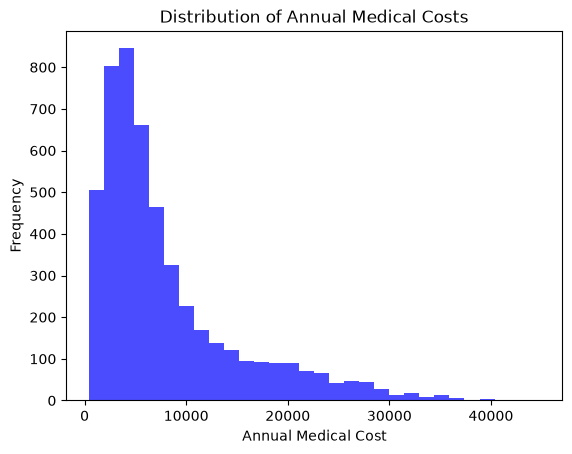

In [618]:
#exploratory data analysis
plt.title('Distribution of Annual Medical Costs')
plt.xlabel('Annual Medical Cost')
plt.ylabel('Frequency')
plt.hist(df['annual_medical_cost'], bins=30, color='blue', alpha=0.7)
plt.show()

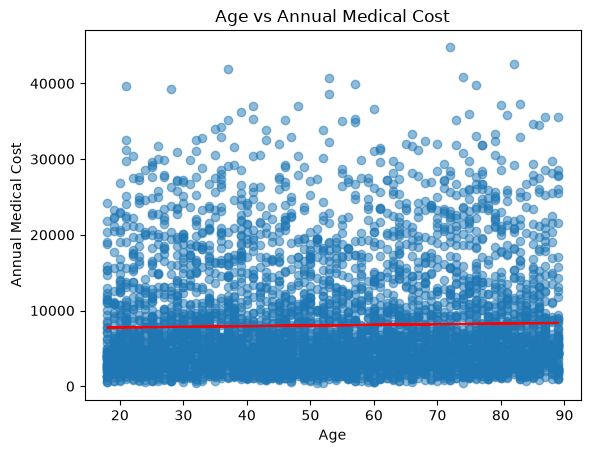

In [619]:
#age vs aannual medical cost
plt.title('Age vs Annual Medical Cost')
plt.xlabel('Age')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['age'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['age'], df['annual_medical_cost'], 1)
plt.plot(df['age'], slope * df['age'] + intercept, color='red')
plt.show()

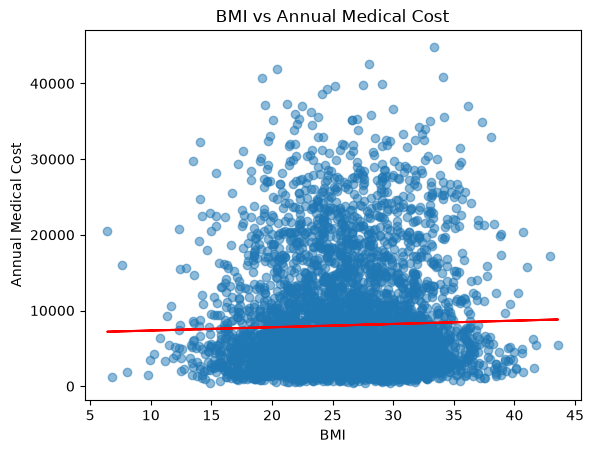

In [620]:
#bmi vs annual medical cost
plt.title('BMI vs Annual Medical Cost')
plt.xlabel('BMI')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['bmi'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['bmi'], df['annual_medical_cost'], 1)
plt.plot(df['bmi'], slope * df['bmi'] + intercept, color='red')
plt.show()

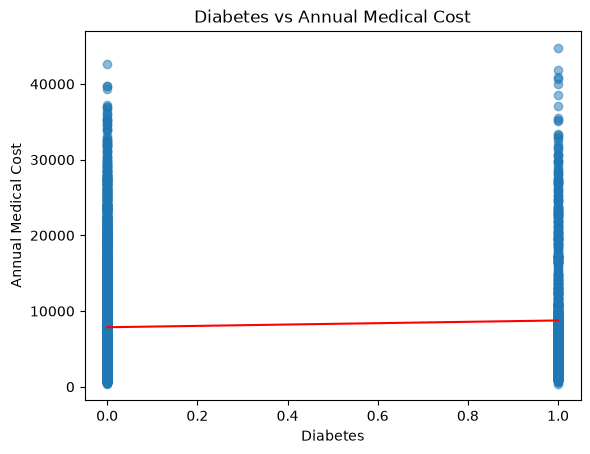

In [621]:
#diabetes vs medical cost
plt.title('Diabetes vs Annual Medical Cost')
plt.xlabel('Diabetes')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['diabetes'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['diabetes'], df['annual_medical_cost'], 1)
plt.plot(df['diabetes'], slope * df['diabetes'] + intercept, color='red')
plt.show()

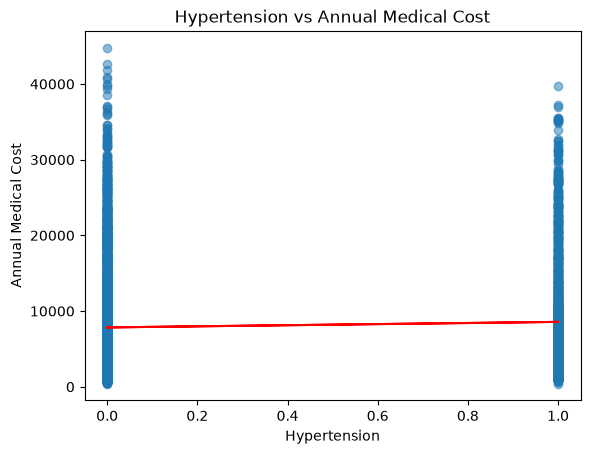

In [622]:
plt.title('Hypertension vs Annual Medical Cost')
plt.xlabel('Hypertension')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['hypertension'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['hypertension'], df['annual_medical_cost'], 1)
plt.plot(df['hypertension'], slope * df['hypertension'] + intercept, color='red')
plt.show()

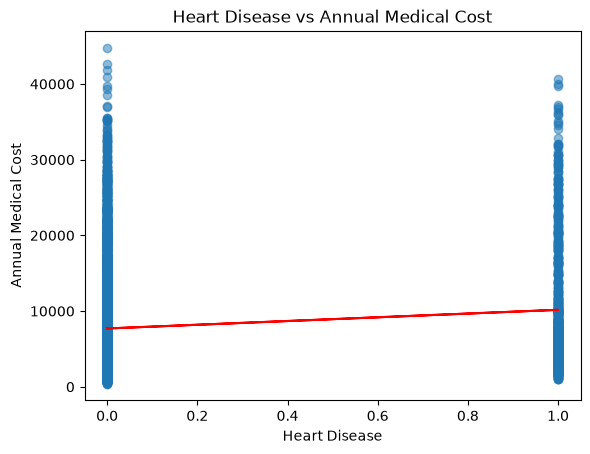

In [623]:
plt.title('Heart Disease vs Annual Medical Cost')
plt.xlabel('Heart Disease')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['heart_disease'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['heart_disease'], df['annual_medical_cost'], 1)
plt.plot(df['heart_disease'], slope * df['heart_disease'] + intercept, color='red')
plt.show()

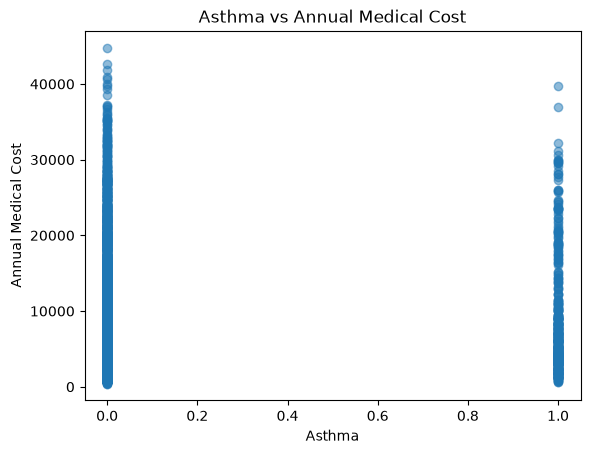

In [624]:
#asthma vs annual medical cost
plt.title('Asthma vs Annual Medical Cost')
plt.xlabel('Asthma')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['asthma'], df['annual_medical_cost'], alpha=0.5)
plt.show()

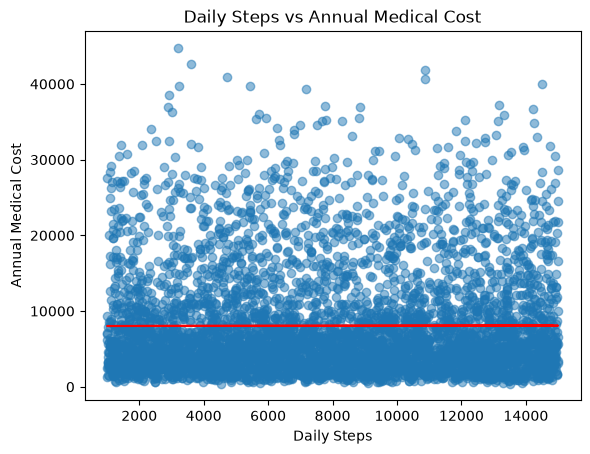

In [625]:
#daily steps vs annual medical cost
plt.title('Daily Steps vs Annual Medical Cost')
plt.xlabel('Daily Steps')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['daily_steps'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['daily_steps'], df['annual_medical_cost'], 1)
plt.plot(df['daily_steps'], slope * df['daily_steps'] + intercept, color='red') 
plt.show()

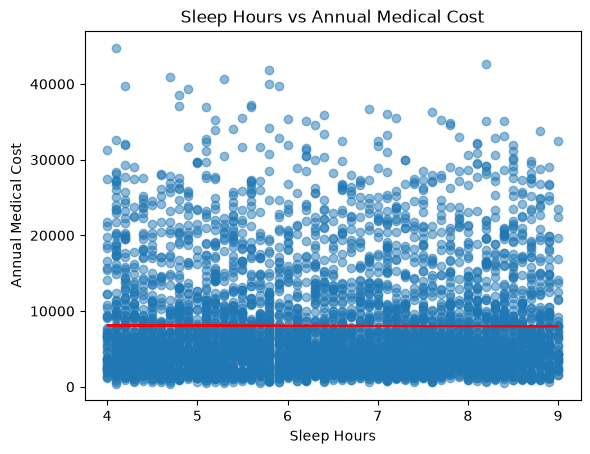

In [626]:
#sleep hours vs annual medical cost
plt.title('Sleep Hours vs Annual Medical Cost')
plt.xlabel('Sleep Hours')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['sleep_hours'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['sleep_hours'], df['annual_medical_cost'], 1)
plt.plot(df['sleep_hours'], slope * df['sleep_hours'] + intercept, color='red')
plt.show()

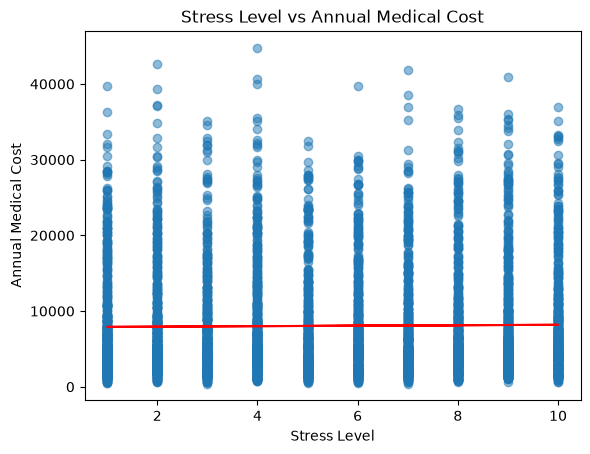

In [627]:
#stress level vs annual medical cost
plt.title('Stress Level vs Annual Medical Cost')
plt.xlabel('Stress Level')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['stress_level'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['stress_level'], df['annual_medical_cost'], 1)
plt.plot(df['stress_level'], slope * df['stress_level'] + intercept, color='red')
plt.show()

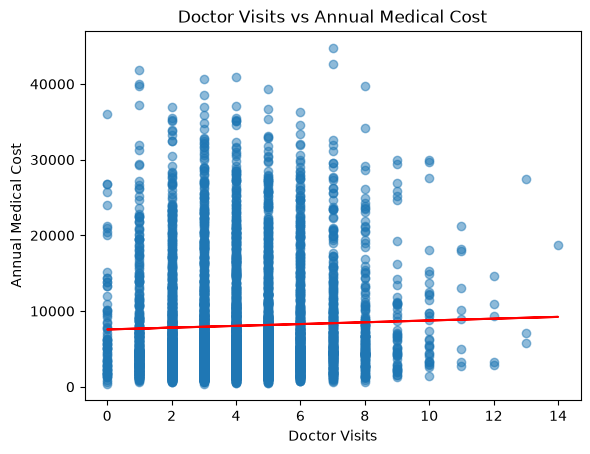

In [628]:
#doctor visits vs annual medical cost
plt.title('Doctor Visits vs Annual Medical Cost')
plt.xlabel('Doctor Visits')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['doctor_visits_per_year'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['doctor_visits_per_year'], df['annual_medical_cost'], 1)
plt.plot(df['doctor_visits_per_year'], slope * df['doctor_visits_per_year'] + intercept, color='red')
plt.show()

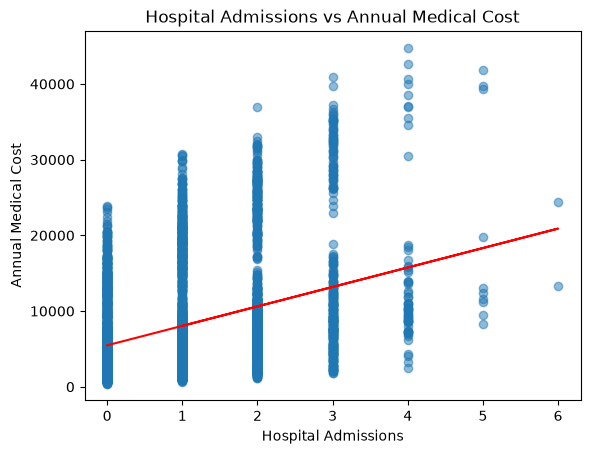

In [629]:
#hospital admissions vs annual medical cost
plt.title('Hospital Admissions vs Annual Medical Cost')
plt.xlabel('Hospital Admissions')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['hospital_admissions'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['hospital_admissions'], df['annual_medical_cost'], 1)
plt.plot(df['hospital_admissions'], slope * df['hospital_admissions'] + intercept, color='red')
plt.show()

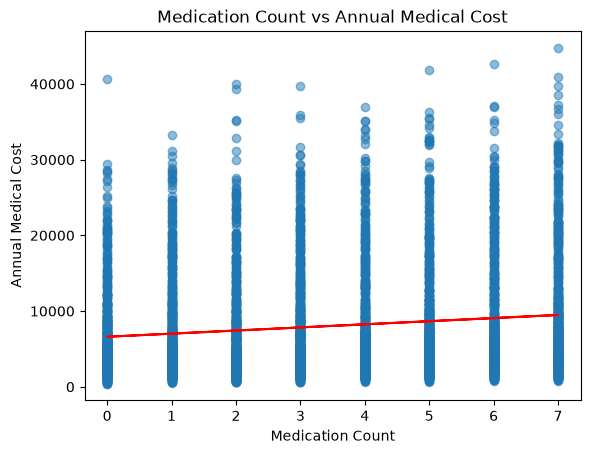

In [630]:
#medication count vs annual medical cost
plt.title('Medication Count vs Annual Medical Cost')
plt.xlabel('Medication Count')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['medication_count'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['medication_count'], df['annual_medical_cost'], 1)
plt.plot(df['medication_count'], slope * df['medication_count'] + intercept, color='red')
plt.show()

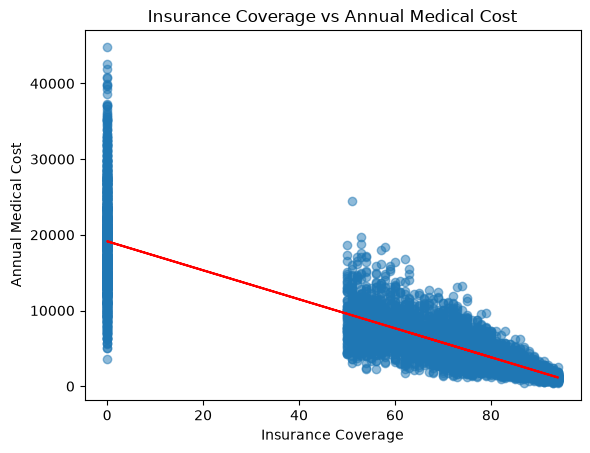

In [631]:
#insurance coverage percentage vs annual medical cost
plt.title('Insurance Coverage vs Annual Medical Cost')
plt.xlabel('Insurance Coverage')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['insurance_coverage_pct'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['insurance_coverage_pct'], df['annual_medical_cost'], 1)
plt.plot(df['insurance_coverage_pct'], slope * df['insurance_coverage_pct'] + intercept, color='red')
plt.show()

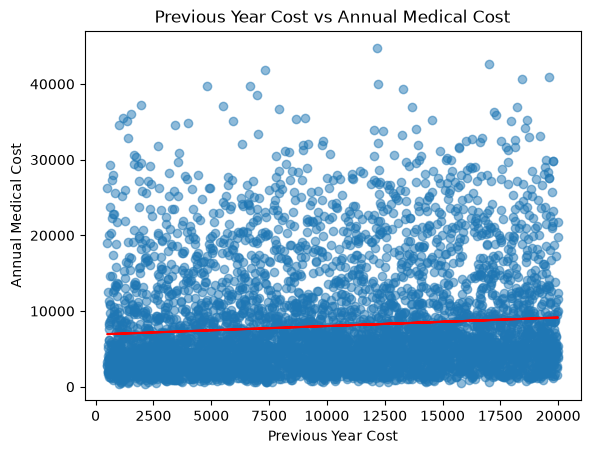

In [632]:
#previous year cost vs annual medical cost
plt.title('Previous Year Cost vs Annual Medical Cost')
plt.xlabel('Previous Year Cost')
plt.ylabel('Annual Medical Cost')
plt.scatter(df['previous_year_cost'], df['annual_medical_cost'], alpha=0.5)

slope, intercept = np.polyfit(df['previous_year_cost'], df['annual_medical_cost'], 1)
plt.plot(df['previous_year_cost'], slope * df['previous_year_cost'] + intercept, color='red')
plt.show()

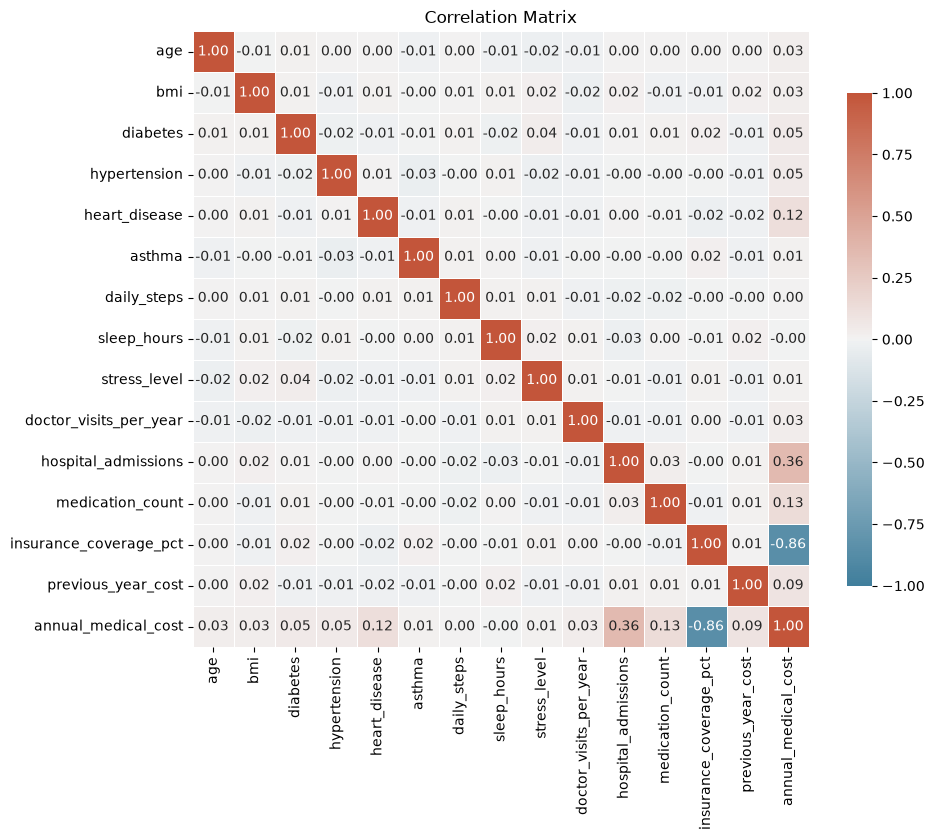

In [633]:
#coorrelation matrix
plt.figure(figsize=(10, 8))

cmap = sns.diverging_palette(230, 20, as_cmap=True)

correlation_matrix = sns.heatmap(df.drop(columns=['gender', 'smoker', 'physical_activity_level', 'insurance_type', 'city_type']).corr(), cmap=cmap, vmax=1.0, vmin=-1.0, center=0, fmt='.2f', linewidths=0.5, square=True, annot=True, cbar_kws={"shrink": .8})

plt.title('Correlation Matrix')
plt.show()

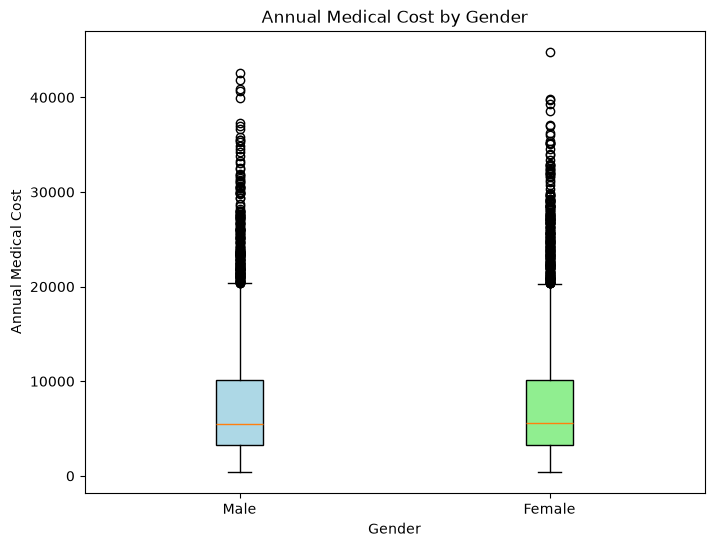

In [634]:
#gender boxplot
fig, ax = plt.subplots(figsize=(8, 6))
bp = ax.boxplot([df[df['gender'] == 'Male']['annual_medical_cost'], df[df['gender'] == 'Female']['annual_medical_cost']], tick_labels=['Male', 'Female'], patch_artist=True)

colors = ['lightblue', 'lightgreen']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax.set_title('Annual Medical Cost by Gender')
ax.set_xlabel('Gender')
ax.set_ylabel('Annual Medical Cost')
plt.show()

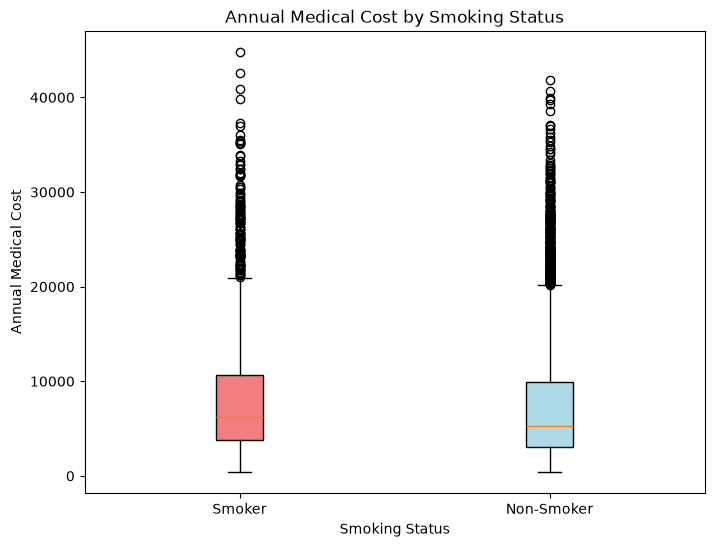

In [635]:
#smoker boxplot
fig, ax = plt.subplots(figsize=(8, 6))
bp = ax.boxplot([df[df['smoker'] == "Yes"]['annual_medical_cost'], df[df['smoker'] == "No"]['annual_medical_cost']], tick_labels=['Smoker', 'Non-Smoker'], patch_artist=True)   

colors = ['lightcoral', 'lightblue']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax.set_title('Annual Medical Cost by Smoking Status')
ax.set_xlabel('Smoking Status')
ax.set_ylabel('Annual Medical Cost')
plt.show()

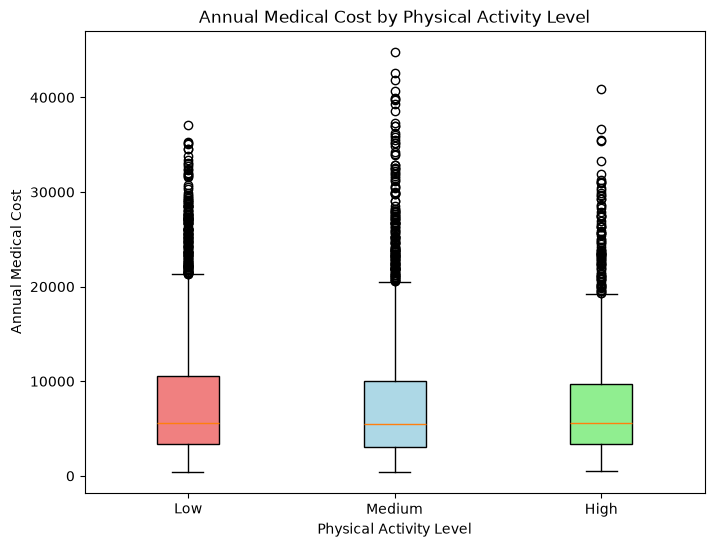

In [636]:
#physical activity level boxplot
fig, ax = plt.subplots(figsize=(8, 6))
bp = ax.boxplot([df[df['physical_activity_level'] == 'Low']['annual_medical_cost'], df[df['physical_activity_level'] == 'Medium']['annual_medical_cost'], df[df['physical_activity_level'] == 'High']['annual_medical_cost']], tick_labels=['Low', 'Medium', 'High'], patch_artist=True)

colors = ['lightcoral', 'lightblue', 'lightgreen']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax.set_title('Annual Medical Cost by Physical Activity Level')
ax.set_xlabel('Physical Activity Level')
ax.set_ylabel('Annual Medical Cost')
plt.show()

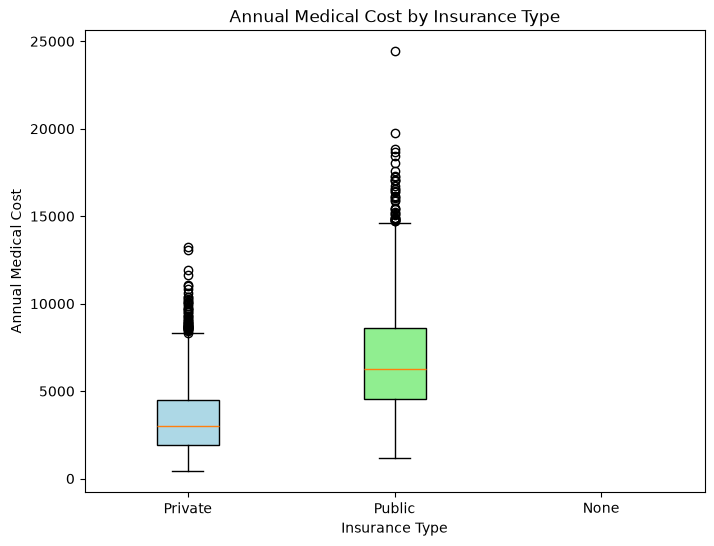

In [637]:
#insurance type vs annual medical cost
fig, ax = plt.subplots(figsize=(8, 6))
bp = ax.boxplot([df[df['insurance_type'] == 'Private']['annual_medical_cost'], df[df['insurance_type'] == 'Government']['annual_medical_cost'], df[df['insurance_type'] == None]['annual_medical_cost']], tick_labels=['Private', 'Public', 'None'], patch_artist=True)

colors = ['lightblue', 'lightgreen', 'lightcoral']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax.set_title('Annual Medical Cost by Insurance Type')
ax.set_xlabel('Insurance Type')
ax.set_ylabel('Annual Medical Cost')
plt.show()

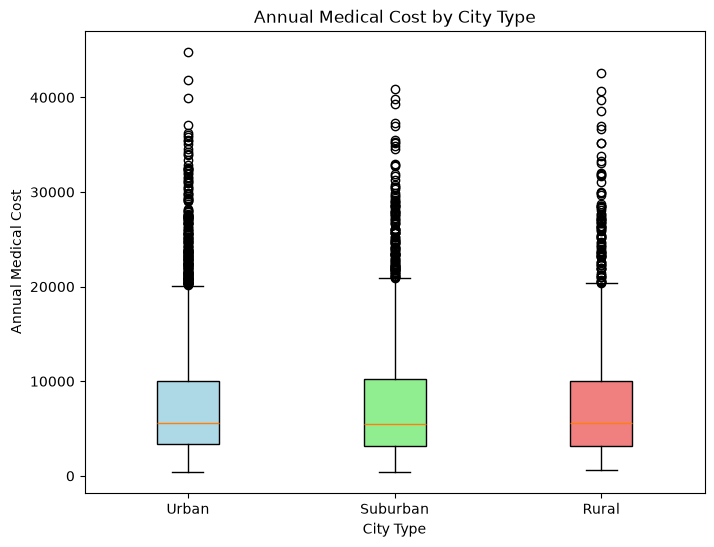

In [638]:
#city type vs annual medical cost
fig, ax = plt.subplots(figsize=(8, 6))
bp = ax.boxplot([df[df['city_type'] == 'Urban']['annual_medical_cost'], df[df['city_type'] == 'Semi-Urban']['annual_medical_cost'], df[df['city_type'] == 'Rural']['annual_medical_cost']], tick_labels=['Urban', 'Suburban', 'Rural'], patch_artist=True)

colors = ['lightblue', 'lightgreen', 'lightcoral']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)

ax.set_title('Annual Medical Cost by City Type')
ax.set_xlabel('City Type')
ax.set_ylabel('Annual Medical Cost')
plt.show()

In [639]:
#Preprocessing

X = df.drop(columns=['annual_medical_cost'])
y = df['annual_medical_cost']

numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

numeric_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
])

categorical_preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
])

scaled_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     categorical_cols),
])

unscaled_preprocessor = ColumnTransformer([
    ("num", "passthrough", numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     categorical_cols),
])

def make_model(preprocesor, estimator):
    pipeline = Pipeline([
        ("preprocessor", preprocesor),
        ("model", estimator)
    ])

    return TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1
    )

models = {
    "Linear Regression": make_model(scaled_preprocessor, LinearRegression()),
    "Ridge Regression": make_model(scaled_preprocessor, Ridge(random_state=SEED)),
    "Random Forest": make_model(unscaled_preprocessor, RandomForestRegressor(random_state=SEED, n_estimators=100, max_depth=None, min_samples_split=2, min_samples_leaf=1)),
    "Dummy Regressor": make_model(unscaled_preprocessor, DummyRegressor(strategy="mean"))
}


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED)

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")
    print(f"{name} R^2: {np.mean(scores):.4f}")

C:\Users\monte\AppData\Local\Temp\ipykernel_25908\2934011776.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


Linear Regression R^2: 0.9539
Ridge Regression R^2: 0.9550
Random Forest R^2: 0.9719
Dummy Regressor R^2: -0.1113


In [640]:
#MLP

#train test split
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.3, random_state=SEED)

#scale the data
mlp_preprocessor = clone(scaled_preprocessor)
X_train_scaled = mlp_preprocessor.fit_transform(X_tr)
X_val_scaled = mlp_preprocessor.transform(X_val)

#log1p target transformation
y_train_log = np.log1p(y_tr.to_numpy(dtype=np.float32))
y_val_log = np.log1p(y_val.to_numpy(dtype=np.float32))

#MLP model
mlp = Sequential([
    keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4)),
    Dropout(0.1),
    Dense(64, activation='relu'),
    Dense(1, activation='linear')
])

In [641]:
#compile the model
optimizer = keras.optimizers.Adam(learning_rate=0.0001)
mlp.compile(optimizer=optimizer, loss='mean_squared_error', metrics=['mean_squared_error'])

#val data early stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
)

#fit the model
mlp.fit(
    X_train_scaled,
    y_train_log,
    validation_data=(X_val_scaled, y_val_log),
    epochs=500,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/500
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 63.3090 - mean_squared_error: 63.3046 - val_loss: 52.2229 - val_mean_squared_error: 52.2184
Epoch 2/500
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 40.6524 - mean_squared_error: 40.6479 - val_loss: 29.3526 - val_mean_squared_error: 29.3481
Epoch 3/500
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 19.5460 - mean_squared_error: 19.5414 - val_loss: 10.9303 - val_mean_squared_error: 10.9257
Epoch 4/500
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 6.1395 - mean_squared_error: 6.1348 - val_loss: 2.7121 - val_mean_squared_error: 2.7074
Epoch 5/500
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.8031 - mean_squared_error: 1.7983 - val_loss: 1.0258 - val_mean_squared_error: 1.0209
Epoch 6/500
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1.0887 - mean_squared_error: 1.0839 - val_loss: 0.7492 - val_mean_squared_error: 0.7443
Epoch 7/500
77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.9183 - mean_squared_error: 0.9134 - val_loss:

In [642]:
def evaluate_model(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    
    return mae, rmse, r2

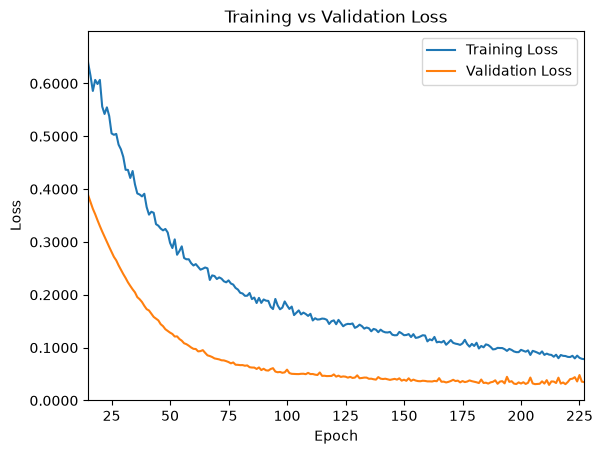

In [643]:
#training vs validation loss plot
history = mlp.history.history

loss = np.asarray(history["loss"])
val_loss = np.asarray(history["val_loss"])

first_epoch = 15  # change this to where you want the zoom to begin
epochs = np.arange(1, len(loss) + 1)

visible = np.concatenate([loss[first_epoch - 1:], val_loss[first_epoch - 1:]])
low, high = visible.min(), visible.max()
padding = max((high - low) * 0.1, 0.001)

fig, ax = plt.subplots()
ax.plot(epochs, loss, label="Training Loss")
ax.plot(epochs, val_loss, label="Validation Loss")
ax.set_xlim(first_epoch, len(epochs))
ax.set_ylim(max(0, low - padding), high + padding)
ax.yaxis.set_major_formatter(FormatStrFormatter("%.4f"))
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Training vs Validation Loss")
ax.legend()
plt.show()

In [644]:
#evaluation
results_df = pd.DataFrame(columns=["Model", "MAE", "RMSE", "R^2"])

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae, rmse, r2 = evaluate_model(y_test, y_pred)
    results_df = pd.concat([results_df, pd.DataFrame([[name, mae, rmse, r2]], columns=["Model", "MAE", "RMSE", "R^2"])], ignore_index=True)

#evaluate MLP
y_pred = np.expm1(mlp.predict(mlp_preprocessor.transform(X_test)).flatten())
mae, rmse, r2 = evaluate_model(y_test, y_pred)
results_df = pd.concat([results_df, pd.DataFrame([["MLP", mae, rmse, r2]], columns=["Model", "MAE", "RMSE", "R^2"])], ignore_index=True)

results_df.sort_values(by="R^2", ascending=False, inplace=True)
results_df.reset_index(drop=True, inplace=True)

results_df

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 652us/step


C:\Users\monte\AppData\Local\Temp\ipykernel_25908\4117490255.py:15: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  results_df.sort_values(by="R^2", ascending=False, inplace=True)
C:\Users\monte\AppData\Local\Temp\ipykernel_25908\4117490255.py:16: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  results_df.reset_index(drop=True, inplace=True)


,Model,MAE,RMSE,R^2
0,MLP,735.718792,1057.843217,0.977452
1,Random Forest,716.314375,1110.242243,0.975163
2,Ridge Regression,828.882145,1407.968523,0.960056
3,Linear Regression,841.550819,1428.656778,0.958873
4,Dummy Regressor,4834.136821,7500.253819,-0.1335


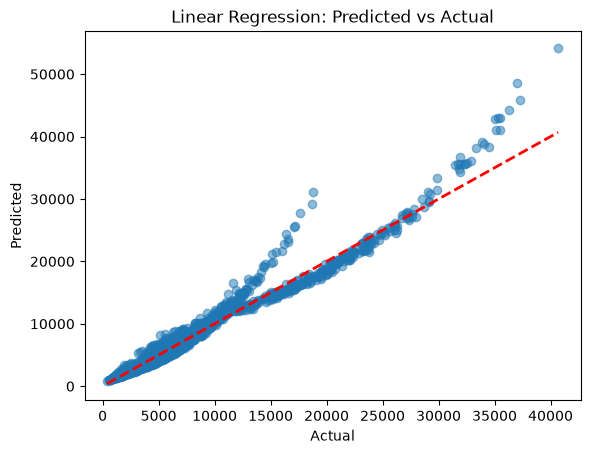

In [645]:
#Linear Regression Predicted vs Actual Plot
linear_model = models["Linear Regression"]
y_pred_linear = linear_model.predict(X_test)

plt.scatter(y_test, y_pred_linear, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Linear Regression: Predicted vs Actual')
plt.show()

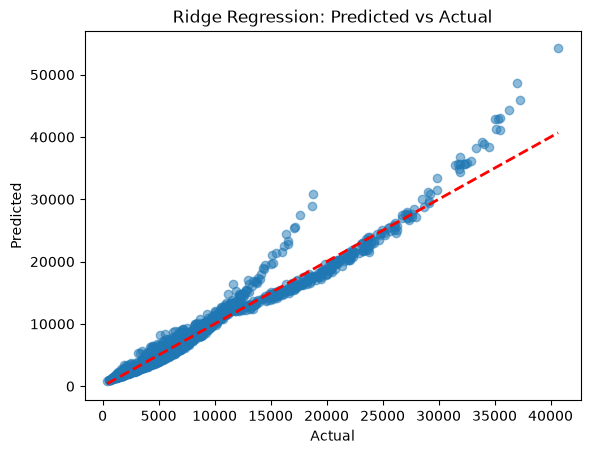

In [646]:
#Ridge Regression Predicted vs Actual Plot
ridge_model = models["Ridge Regression"]
y_pred_ridge = ridge_model.predict(X_test)

plt.scatter(y_test, y_pred_ridge, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Ridge Regression: Predicted vs Actual')
plt.show()

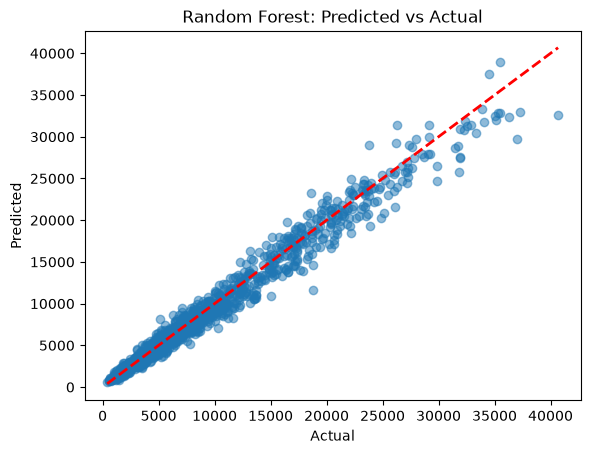

In [647]:
#Random Forest Predicted vs Actual Plot
rf_model = models["Random Forest"]
y_pred_rf = rf_model.predict(X_test)

plt.scatter(y_test, y_pred_rf, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Random Forest: Predicted vs Actual')
plt.show()

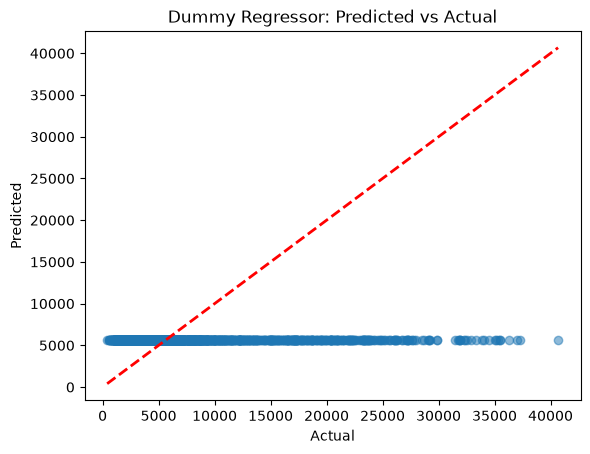

In [648]:
#Dummy Regressor Predicted vs Actual Plot
dummy_model = models["Dummy Regressor"]
y_pred_dummy = dummy_model.predict(X_test)

plt.scatter(y_test, y_pred_dummy, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Dummy Regressor: Predicted vs Actual')
plt.show()

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 457us/step


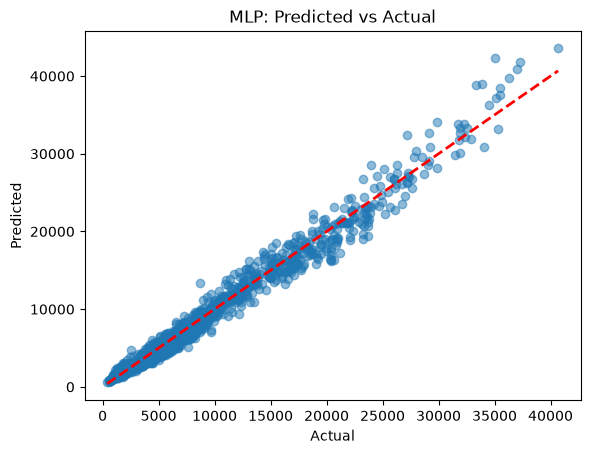

In [649]:
#MLP Predicted vs Actual Plot
y_pred_mlp = np.expm1(mlp.predict(mlp_preprocessor.transform(X_test)).flatten())

plt.scatter(y_test, y_pred_mlp, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('MLP: Predicted vs Actual')
plt.show()


In [650]:
#feature importance for Random Forest
rf_model = models["Random Forest"]
pipeline = rf_model.regressor_  # fitted pipeline inside the wrapper
forest = pipeline.named_steps["model"]
preprocessor = pipeline.named_steps["preprocessor"]

feature_importance = pd.Series(
    forest.feature_importances_,
    index=preprocessor.get_feature_names_out()
).sort_values(ascending=False)

display(feature_importance)

num__insurance_coverage_pct            0.747587
num__hospital_admissions               0.129384
cat__insurance_type_Government         0.033207
num__previous_year_cost                0.019346
cat__insurance_type_None               0.017734
num__medication_count                  0.017241
num__heart_disease                     0.008152
num__age                               0.003162
num__doctor_visits_per_year            0.002973
num__daily_steps                       0.002973
num__bmi                               0.002765
num__stress_level                      0.002619
num__sleep_hours                       0.002505
num__diabetes                          0.001995
cat__smoker_Yes                        0.001950
cat__smoker_No                         0.001932
num__hypertension                      0.001635
cat__physical_activity_level_Low       0.000360
cat__city_type_Urban                   0.000348
cat__physical_activity_level_Medium    0.000343
cat__city_type_Semi-Urban              0

In [651]:
#linear regression coefficients
linear_model = models["Linear Regression"]
coefficients = linear_model.regressor_.named_steps["model"].coef_
preprocessor = linear_model.regressor_.named_steps["preprocessor"]
feature_names = preprocessor.get_feature_names_out()

coefficients = pd.Series(
    coefficients.ravel(),
    index=feature_names
).sort_values(key=abs, ascending=False)

display(coefficients)

num__insurance_coverage_pct           -1.357549
cat__insurance_type_None              -1.126140
cat__insurance_type_Government         0.566842
cat__insurance_type_Private            0.559298
num__hospital_admissions               0.303254
num__medication_count                  0.107595
num__previous_year_cost                0.105279
num__heart_disease                     0.095248
cat__smoker_Yes                        0.088339
cat__smoker_No                        -0.088339
num__diabetes                          0.057546
num__hypertension                      0.054524
num__doctor_visits_per_year            0.043243
num__stress_level                      0.035910
num__asthma                            0.027419
num__age                               0.023277
num__bmi                               0.009656
cat__physical_activity_level_High      0.007909
cat__physical_activity_level_Medium   -0.006696
num__sleep_hours                       0.005108
num__daily_steps                      -0

In [652]:
#Ridge Regression coefficients
ridge_model = models["Ridge Regression"]
pipeline = ridge_model.regressor_

ridge_estimator = pipeline.named_steps["model"]
preprocessor = pipeline.named_steps["preprocessor"]
feature_names = preprocessor.get_feature_names_out()

ridge_coefficients = pd.Series(
    ridge_estimator.coef_.ravel(),
    index=feature_names
).sort_values(key=abs, ascending=False)

display(ridge_coefficients)

num__insurance_coverage_pct           -1.335538
cat__insurance_type_None              -1.090988
cat__insurance_type_Government         0.555236
cat__insurance_type_Private            0.535752
num__hospital_admissions               0.303244
num__medication_count                  0.107504
num__previous_year_cost                0.105226
num__heart_disease                     0.095168
cat__smoker_Yes                        0.088329
cat__smoker_No                        -0.088329
num__diabetes                          0.057551
num__hypertension                      0.054465
num__doctor_visits_per_year            0.043208
num__stress_level                      0.035792
num__asthma                            0.027277
num__age                               0.023280
num__bmi                               0.009693
cat__physical_activity_level_High      0.007880
cat__physical_activity_level_Medium   -0.006579
num__sleep_hours                       0.005167
num__daily_steps                      -0

In [653]:
class FittedKerasRegressor(RegressorMixin, BaseEstimator):
    def __init__(self, model, preprocessor):
        self.model = model
        self.preprocessor = preprocessor

    def fit(self, X, y=None):
        return self

    def __sklearn_is_fitted__(self):
        return True

    def predict(self, X):
        X_processed = self.preprocessor.transform(X).astype("float32")
        predictions_log = self.model.predict(X_processed, verbose=0).ravel()
        return np.expm1(predictions_log)

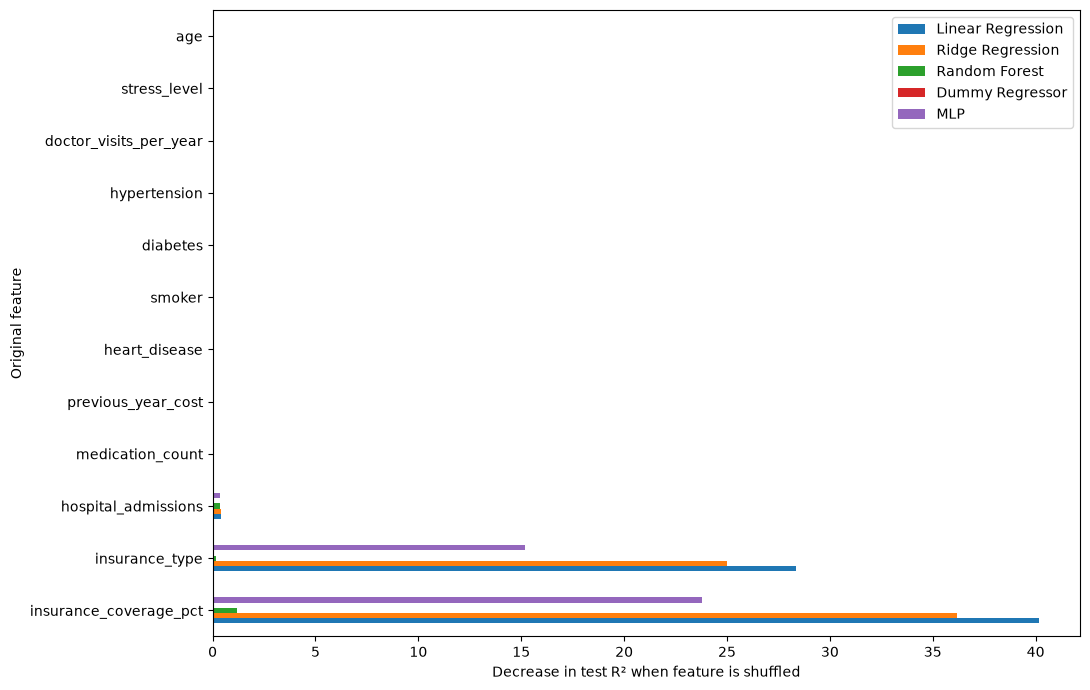

In [654]:
estimators = {
    **models,
    "MLP": FittedKerasRegressor(mlp, mlp_preprocessor),
}

importance_results = {}

for name, estimator in estimators.items():
    result = permutation_importance(
        estimator,
        X_test,
        y_test,
        scoring="r2",
        n_repeats=20,
        random_state=SEED,
        n_jobs=-1,
    )
    importance_results[name] = pd.Series(
        result.importances_mean,
        index=X_test.columns,
    )

importance_df = pd.DataFrame(importance_results)

# Plot the 12 features with the highest average importance across models.
top_features = importance_df.mean(axis=1).nlargest(12).index
ax = importance_df.loc[top_features].plot.barh(figsize=(11, 7))
ax.set_xlabel("Decrease in test R² when feature is shuffled")
ax.set_ylabel("Original feature")
plt.tight_layout()
plt.show()